# Feature Selection and Baseline Modelling

## Objective

This notebook compares simple match-outcome models and decides which features and preprocessing choices should move forward.

It uses the chronologically separated `train_processed.csv` and `validation_processed.csv` files created in Notebook 03. The **2015/16 test file is deliberately not loaded**. Every feature ranking, model comparison, threshold check, PCA fit, and scaling decision uses only training and validation data.

The notebook produces:

- filter-based and model-based feature evidence,
- a selected set of 40 interpretable features,
- validation comparisons using Macro F1 as the primary metric and accuracy as the secondary metric, and
- decisions for Notebook 05, where final candidate models will be fitted and selected.

## 1. Imports and Project Paths

The imports are collected in one place. Fixed random seeds make the experiments as reproducible as the installed scikit-learn version allows; small tree-model differences can occur across library versions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data" / "processed").exists():
    raise FileNotFoundError(
        "Could not find data/processed. Start Jupyter from the project root "
        "or from the notebooks folder."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CLASS_ORDER = ["Home Win", "Draw", "Away Win"]
model_results = []

Matplotlib is building the font cache; this may take a moment.


## 2. Load Processed Training and Validation Data

Each processed file already contains numeric columns only. The `target` column is separated from the predictors before fitting.

We check that both splits have the same columns and that neither contains missing or infinite values. The test filename never appears in the loading code below, which keeps the final season untouched.

In [2]:
train_data = pd.read_csv(PROCESSED_DIR / "train_processed.csv")
validation_data = pd.read_csv(PROCESSED_DIR / "validation_processed.csv")

X_train = train_data.drop(columns="target")
y_train = train_data["target"]
X_val = validation_data.drop(columns="target")
y_val = validation_data["target"]

assert X_train.columns.equals(X_val.columns)
assert X_train.isna().sum().sum() == 0
assert X_val.isna().sum().sum() == 0
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_val.to_numpy()).all()

split_summary = pd.DataFrame(
    {
        "Split": ["Training (2010/11–2013/14)", "Validation (2014/15)"],
        "Matches": [len(X_train), len(X_val)],
        "Predictors": [X_train.shape[1], X_val.shape[1]],
    }
)
display(split_summary)
display(y_train.value_counts(normalize=True).mul(100).round(2).rename("Training percent"))

,Split,Matches,Predictors
0,Training (2010/11–2013/14),11413,80
1,Validation (2014/15),3067,80


target
Home Win    46.21
Away Win    28.66
Draw        25.13
Name: Training percent, dtype: float64

### Finding

The model receives 80 processed predictors. Home Win is the largest class and Draw is the hardest outcome in the experiments, so **Macro F1** is the main comparison metric: it gives each of the three classes equal importance. Accuracy remains useful, but it can hide weak Draw performance.

## 3. Dummy Baseline

A model is useful only if it improves on a rule that requires no football knowledge. `DummyClassifier(strategy="most_frequent")` always predicts the largest training class.

Its low Macro F1 is especially informative: predicting only one class gives zero useful performance for the other two outcomes.

In [3]:
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_predictions = dummy_model.predict(X_val)

dummy_accuracy = accuracy_score(y_val, dummy_predictions)
dummy_macro_f1 = f1_score(y_val, dummy_predictions, average="macro")

model_results.append(
    {
        "Model": "Dummy (most frequent)",
        "Feature Set": "All 80",
        "Scaling": "None",
        "Accuracy": dummy_accuracy,
        "Macro F1": dummy_macro_f1,
    }
)

pd.DataFrame(model_results).tail(1)

,Model,Feature Set,Scaling,Accuracy,Macro F1
0,Dummy (most frequent),All 80,None,0.447995,0.20626


### Finding

The dummy model records about **0.448 accuracy** but only about **0.206 Macro F1**. This gap shows why accuracy alone is not enough for this three-class task.

## 4. Initial Random Forest

The first real baseline uses all processed features. Random Forest can model nonlinear relationships and interactions without scaling, so it is a useful starting point for both performance and feature importance.

In [4]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_val)

rf_accuracy = accuracy_score(y_val, rf_predictions)
rf_macro_f1 = f1_score(y_val, rf_predictions, average="macro")

model_results.append(
    {
        "Model": "Random Forest",
        "Feature Set": "All 80",
        "Scaling": "None",
        "Accuracy": rf_accuracy,
        "Macro F1": rf_macro_f1,
    }
)

display(pd.DataFrame(model_results).tail(1))
print(classification_report(y_val, rf_predictions, labels=CLASS_ORDER, zero_division=0))

,Model,Feature Set,Scaling,Accuracy,Macro F1
1,Random Forest,All 80,None,0.511249,0.388879


              precision    recall  f1-score   support

    Home Win       0.52      0.82      0.64      1374
        Draw       0.26      0.03      0.05       787
    Away Win       0.51      0.46      0.48       906

    accuracy                           0.51      3067
   macro avg       0.43      0.44      0.39      3067
weighted avg       0.45      0.51      0.44      3067



### Finding

The original project run recorded approximately **0.511 accuracy** and **0.389 Macro F1**. The classification report is the important diagnostic: the model predicts Home Win reasonably often but has extremely poor Draw recall. A model can therefore beat the dummy on accuracy while still handling the classes unevenly.

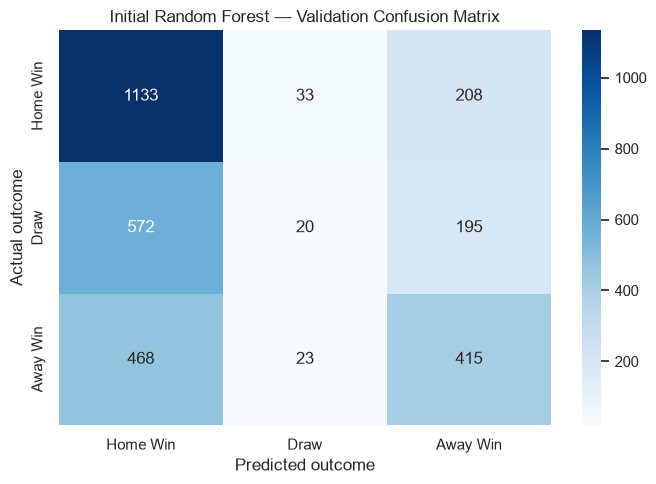

In [5]:
rf_confusion = confusion_matrix(y_val, rf_predictions, labels=CLASS_ORDER)

plt.figure(figsize=(7, 5))
sns.heatmap(
    rf_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
)
plt.title("Initial Random Forest — Validation Confusion Matrix")
plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "random_forest_confusion_matrix.png", dpi=150)
plt.show()

## 5. Statistical and Filter-Based Feature Analysis

Filter methods inspect the training data without choosing features from test performance.

### 5.1 Variance check

A constant column cannot separate outcomes because it never changes. `VarianceThreshold(0)` checks for such columns; it is fitted to training data only.

In [6]:
variance_selector = VarianceThreshold(threshold=0)
variance_selector.fit(X_train)
constant_features = X_train.columns[~variance_selector.get_support()].tolist()

print("Constant features:", constant_features)

Constant features: []


### Finding

No constant features remain in the saved processed training data. Notebook 03 already performed this quality check before export.

### 5.2 Correlation analysis

Correlation identifies pairs that carry very similar linear information. Before the processed splits were saved, Notebook 03 found that `home_players_listed` and `away_players_listed` were each above 0.96 correlation with their corresponding `players_with_attributes` count, so the two `players_listed` columns were removed.

High correlation is not an automatic reason to delete a potentially useful football feature. In particular, overall rating and potential were deliberately retained for model-based evaluation.

In [7]:
correlation_audit_path = TABLES_DIR / "highly_correlated_features.csv"
high_correlation_pairs = pd.read_csv(correlation_audit_path)
display(high_correlation_pairs)

processed_correlation = X_train.corr().abs()
upper_triangle = processed_correlation.where(
    np.triu(np.ones(processed_correlation.shape), k=1).astype(bool)
)
remaining_high_pairs = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
    .query("correlation > 0.95")
    .sort_values("correlation", ascending=False)
)
display(remaining_high_pairs)

,feature_1,feature_2,correlation
0,away_players_with_attributes,away_players_listed,0.971810
1,home_players_with_attributes,home_players_listed,0.967818
2,away_avg_potential,away_avg_overall_rating,0.952421
3,home_avg_potential,home_avg_overall_rating,0.953087


,feature_1,feature_2,correlation
2108,home_avg_overall_rating,home_avg_potential,0.953087
2027,away_avg_overall_rating,away_avg_potential,0.952421


### 5.3 Mutual Information

Mutual Information (MI) measures how much knowing a feature reduces uncertainty about the outcome. Unlike ordinary correlation, it can detect some nonlinear relationships.

MI is a ranking aid, not proof of causation. We calculate it on the training split only and retain the full scores for auditability.

,feature,mutual_information
0,potential_diff,0.071494
1,passing_diff,0.070241
2,overall_rating_diff,0.069146
3,technical_diff,0.066344
4,attack_diff,0.056555
5,pace_diff,0.035464
6,recent_goals_scored_diff,0.033652
7,form_points_diff,0.031415
8,away_avg_overall_rating,0.027292
9,home_avg_technical,0.026592


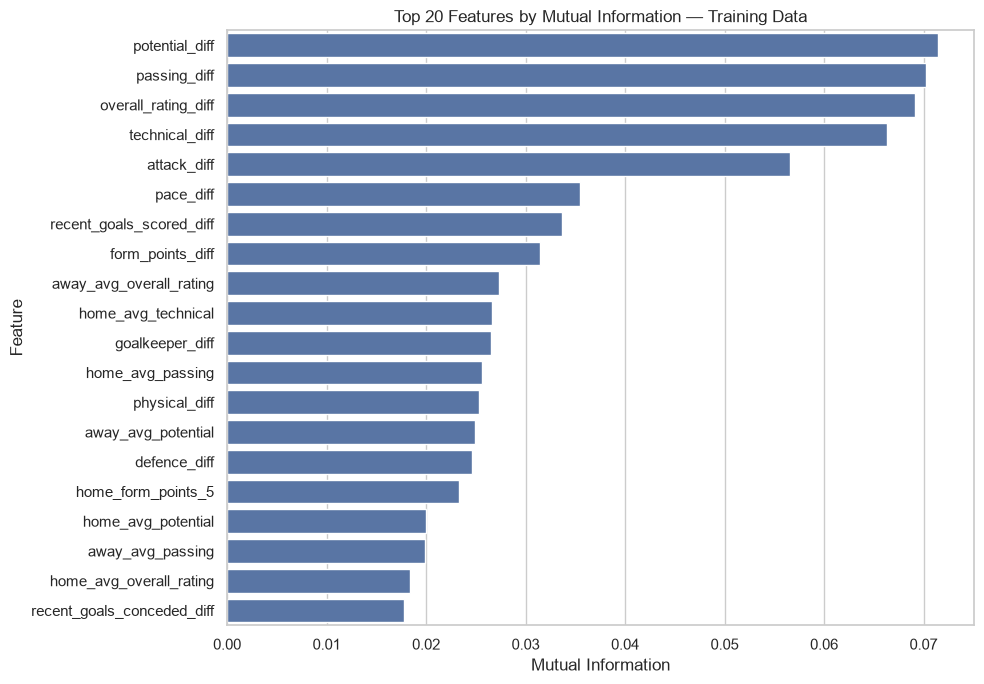

In [8]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

mi_scores = mutual_info_classif(
    X_train,
    y_train_encoded,
    random_state=RANDOM_STATE,
)
mi_results = (
    pd.DataFrame(
        {"feature": X_train.columns, "mutual_information": mi_scores}
    )
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)
mi_results.to_csv(TABLES_DIR / "mutual_information_scores.csv", index=False)
display(mi_results.head(20))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=mi_results.head(20),
    x="mutual_information",
    y="feature",
    color="#4C72B0",
)
plt.title("Top 20 Features by Mutual Information — Training Data")
plt.xlabel("Mutual Information")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_features_mutual_information.png", dpi=150)
plt.show()

### Finding

Relative-strength variables such as overall rating, passing, potential, technical skill, and attack differences rank strongly. This supports the football idea that the gap between the two teams is often more informative than either team's strength in isolation.

## 6. Random Forest Feature Importance

The fitted Random Forest supplies a model-based importance score: features that help its trees make useful splits receive more importance. These scores reflect this model and training period, so we combine them with MI, correlation, and validation evidence rather than treating them as universal truth.

,feature,importance
0,overall_rating_diff,0.032009
1,potential_diff,0.029574
2,passing_diff,0.028607
3,technical_diff,0.028521
4,attack_diff,0.023615
5,pace_diff,0.021273
6,physical_diff,0.020711
7,home_avg_technical,0.019264
8,defence_diff,0.019118
9,goalkeeper_diff,0.018922


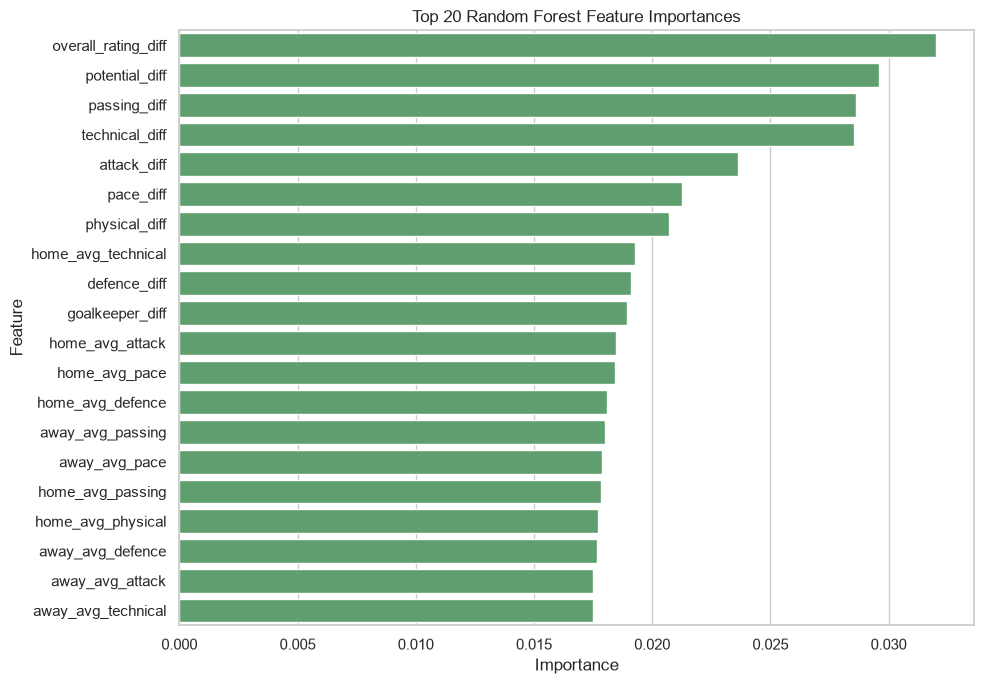

In [9]:
feature_importance = (
    pd.DataFrame(
        {
            "feature": X_train.columns,
            "importance": rf_model.feature_importances_,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
feature_importance.to_csv(
    TABLES_DIR / "random_forest_feature_importance.csv",
    index=False,
)
display(feature_importance.head(20))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(20),
    x="importance",
    y="feature",
    color="#55A868",
)
plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "random_forest_feature_importance.png", dpi=150)
plt.show()

### Finding

The leading group again contains `overall_rating_diff`, `potential_diff`, `passing_diff`, `technical_diff`, `attack_diff`, `pace_diff`, `physical_diff`, and `defence_diff`. Relative team strength therefore has both statistical support and a clear football interpretation.

## 7. Feature-Count Experiment

A ranking alone does not tell us how many features to keep. We therefore train the same Random Forest with all features and with the top 10, 20, 30, and 40 importance-ranked features. Only the number of columns changes.

Validation Macro F1 is the primary decision metric. Small numerical differences can vary slightly by scikit-learn version, so the conclusion should depend on the pattern rather than the last decimal place.

In [10]:
feature_set_sizes = [10, 20, 30, 40]
feature_count_rows = [
    {
        "Feature Set": "All Features",
        "Number of Features": X_train.shape[1],
        "Accuracy": rf_accuracy,
        "Macro F1": rf_macro_f1,
    }
]

for feature_count in feature_set_sizes:
    selected_features = feature_importance.head(feature_count)["feature"].tolist()
    comparison_model = RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    comparison_model.fit(X_train[selected_features], y_train)
    comparison_predictions = comparison_model.predict(X_val[selected_features])

    feature_count_rows.append(
        {
            "Feature Set": f"Top {feature_count}",
            "Number of Features": feature_count,
            "Accuracy": accuracy_score(y_val, comparison_predictions),
            "Macro F1": f1_score(
                y_val,
                comparison_predictions,
                average="macro",
            ),
        }
    )

feature_selection_comparison = pd.DataFrame(feature_count_rows)
feature_selection_comparison.to_csv(
    TABLES_DIR / "feature_selection_comparison.csv",
    index=False,
)
display(feature_selection_comparison)

,Feature Set,Number of Features,Accuracy,Macro F1
0,All Features,80,0.511249,0.388879
1,Top 10,10,0.498207,0.391163
2,Top 20,20,0.501141,0.392226
3,Top 30,30,0.507336,0.392021
4,Top 40,40,0.512553,0.392978


### Decision: retain the Top 40

The original project run recorded the following approximate pattern: all features `0.511 / 0.389`, Top 10 `0.498 / 0.391`, Top 20 `0.501 / 0.392`, Top 30 `0.507 / 0.392`, and Top 40 `0.513 / 0.393` for accuracy/Macro F1.

Top 40 retains half of the processed columns while producing the strongest validation result in that comparison. It is therefore selected for the remaining interpretable-feature experiments and for Notebook 05.

In [11]:
top_40_features = feature_importance.head(40)["feature"].tolist()
pd.DataFrame({"feature": top_40_features}).to_csv(
    TABLES_DIR / "selected_top40_features.csv",
    index=False,
)

X_train_40 = X_train[top_40_features].copy()
X_val_40 = X_val[top_40_features].copy()

print("Selected features:", X_train_40.shape[1])
display(pd.DataFrame({"feature": top_40_features}))

Selected features: 40


,feature
0,overall_rating_diff
1,potential_diff
2,passing_diff
3,technical_diff
4,attack_diff
5,pace_diff
6,physical_diff
7,home_avg_technical
8,defence_diff
9,goalkeeper_diff


## 8. Balanced Random Forest

The initial forest almost ignored Draw. A class-weighted forest gives each class equal total training influence so errors on the smaller classes matter more during fitting.

This is still a tree model, so scaling is unnecessary.

In [12]:
balanced_rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
balanced_rf_model.fit(X_train_40, y_train)
balanced_rf_predictions = balanced_rf_model.predict(X_val_40)

balanced_rf_accuracy = accuracy_score(y_val, balanced_rf_predictions)
balanced_rf_macro_f1 = f1_score(
    y_val,
    balanced_rf_predictions,
    average="macro",
)

model_results.append(
    {
        "Model": "Balanced Random Forest",
        "Feature Set": "Top 40",
        "Scaling": "None",
        "Accuracy": balanced_rf_accuracy,
        "Macro F1": balanced_rf_macro_f1,
    }
)

display(pd.DataFrame(model_results).tail(1))
print(classification_report(
    y_val,
    balanced_rf_predictions,
    labels=CLASS_ORDER,
    zero_division=0,
))

,Model,Feature Set,Scaling,Accuracy,Macro F1
2,Balanced Random Forest,Top 40,None,0.50538,0.444683


              precision    recall  f1-score   support

    Home Win       0.57      0.69      0.63      1374
        Draw       0.31      0.16      0.21       787
    Away Win       0.47      0.52      0.50       906

    accuracy                           0.51      3067
   macro avg       0.45      0.46      0.44      3067
weighted avg       0.48      0.51      0.48      3067



### Finding

The balanced forest sacrifices some raw accuracy but substantially improves Draw recall and Macro F1 compared with the unrestricted forest. The original run was approximately **0.505 accuracy** and **0.445 Macro F1**; exact tree results can move slightly across library versions.

## 9. Logistic Regression Experiment

Logistic Regression is a simpler linear baseline. It cannot create the same nonlinear interactions as a forest, but its coefficients offer a useful contrast. Class balancing is retained so the model does not learn that nearly ignoring Draw is acceptable.

The completed experiment uses all 80 processed features and `StandardScaler`. The scaler is fitted on training data only, then reused to transform validation data. Section 13 later performs the requested controlled scaling comparison on the selected Top 40 features.

In [13]:
logistic_scaler = StandardScaler()
X_train_logistic = logistic_scaler.fit_transform(X_train)
X_val_logistic = logistic_scaler.transform(X_val)

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE,
)
logistic_model.fit(X_train_logistic, y_train)
logistic_predictions = logistic_model.predict(X_val_logistic)

logistic_accuracy = accuracy_score(y_val, logistic_predictions)
logistic_macro_f1 = f1_score(y_val, logistic_predictions, average="macro")

model_results.append(
    {
        "Model": "Logistic Regression",
        "Feature Set": "All 80",
        "Scaling": "Standard",
        "Accuracy": logistic_accuracy,
        "Macro F1": logistic_macro_f1,
    }
)

display(pd.DataFrame(model_results).tail(1))
print(classification_report(
    y_val,
    logistic_predictions,
    labels=CLASS_ORDER,
    zero_division=0,
))

,Model,Feature Set,Scaling,Accuracy,Macro F1
3,Logistic Regression,All 80,Standard,0.483208,0.438263


              precision    recall  f1-score   support

    Home Win       0.62      0.56      0.59      1374
        Draw       0.28      0.17      0.21       787
    Away Win       0.43      0.64      0.52       906

    accuracy                           0.48      3067
   macro avg       0.44      0.46      0.44      3067
weighted avg       0.48      0.48      0.47      3067



### Finding

The completed run records approximately **0.483 accuracy** and **0.438 Macro F1**. The linear model predicts more Draws than the initial forest and remains competitive on Macro F1. Keeping it is useful even when it is not the best model because it shows how much can be achieved without complex nonlinear decision boundaries.

## 10. Draw Threshold Experiment

The ordinary decision rule chooses the class with the highest probability. Because Draw is difficult, we briefly test whether forcing Draw whenever its estimated probability crosses a chosen threshold improves validation performance.

This is deliberately a short diagnostic, not a long threshold-tuning exercise.

In [14]:
logistic_probabilities = logistic_model.predict_proba(X_val_logistic)
draw_index = list(logistic_model.classes_).index("Draw")
threshold_rows = []

for draw_threshold in [0.20, 0.25, 0.30, 0.35, 0.40]:
    threshold_predictions = logistic_model.classes_[
        logistic_probabilities.argmax(axis=1)
    ].copy()
    threshold_predictions[
        logistic_probabilities[:, draw_index] >= draw_threshold
    ] = "Draw"

    threshold_rows.append(
        {
            "Draw Threshold": draw_threshold,
            "Accuracy": accuracy_score(y_val, threshold_predictions),
            "Macro F1": f1_score(
                y_val,
                threshold_predictions,
                average="macro",
            ),
            "Draw Recall": recall_score(
                y_val,
                threshold_predictions,
                labels=["Draw"],
                average=None,
            )[0],
        }
    )

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.loc[
    threshold_results["Macro F1"].idxmax()
]
display(threshold_results)

threshold_f1_gain = best_threshold_row["Macro F1"] - logistic_macro_f1
threshold_accuracy_change = best_threshold_row["Accuracy"] - logistic_accuracy
display(
    Markdown(
        f"**Interpretation:** the best tested threshold was "
        f"`{best_threshold_row['Draw Threshold']:.3f}`. It changed Macro F1 by "
        f"`{threshold_f1_gain:+.3f}` and accuracy by "
        f"`{threshold_accuracy_change:+.3f}` relative to the ordinary logistic "
        "decision rule. The small trade-off and validation-specific rule were not "
        "worth carrying forward as the main approach."
    )
)

,Draw Threshold,Accuracy,Macro F1,Draw Recall
0,0.20,0.283339,0.186899,0.991105
1,0.25,0.327030,0.276944,0.921220
2,0.30,0.397131,0.395013,0.689962
3,0.35,0.460385,0.443153,0.299873
4,0.40,0.482556,0.438364,0.174079


**Interpretation:** the best tested threshold was `0.350`. It changed Macro F1 by `+0.005` and accuracy by `-0.023` relative to the ordinary logistic decision rule. The small trade-off and validation-specific rule were not worth carrying forward as the main approach.

## 11. Gradient Boosting

Gradient Boosting builds small trees sequentially, with each new tree focusing on errors left by earlier trees. Training sample weights balance the three outcomes. This cell runs the single selected configuration from the completed experiment; it does not repeat the earlier long tuning loop.

Like Random Forest, this tree-based model does not require feature scaling.

In [15]:
balanced_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train,
)

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE,
)
gradient_boosting_model.fit(
    X_train,
    y_train,
    sample_weight=balanced_sample_weights,
)
gradient_boosting_predictions = gradient_boosting_model.predict(X_val)

gradient_boosting_accuracy = accuracy_score(
    y_val,
    gradient_boosting_predictions,
)
gradient_boosting_macro_f1 = f1_score(
    y_val,
    gradient_boosting_predictions,
    average="macro",
)

model_results.append(
    {
        "Model": "Gradient Boosting",
        "Feature Set": "All 80",
        "Scaling": "None",
        "Accuracy": gradient_boosting_accuracy,
        "Macro F1": gradient_boosting_macro_f1,
    }
)

display(pd.DataFrame(model_results).tail(1))
print(classification_report(
    y_val,
    gradient_boosting_predictions,
    labels=CLASS_ORDER,
    zero_division=0,
))

,Model,Feature Set,Scaling,Accuracy,Macro F1
4,Gradient Boosting,All 80,None,0.473753,0.454516


              precision    recall  f1-score   support

    Home Win       0.61      0.54      0.57      1374
        Draw       0.28      0.32      0.30       787
    Away Win       0.47      0.51      0.49       906

    accuracy                           0.47      3067
   macro avg       0.46      0.46      0.45      3067
weighted avg       0.49      0.47      0.48      3067



### Finding

Gradient Boosting records lower accuracy than the initial forest but the strongest Macro F1 among the main model experiments (approximately **0.474 accuracy** and **0.455 Macro F1** in the completed project run). Its predictions are more balanced across Home Win, Draw, and Away Win, and Draw recall improves substantially.

## 12. PCA Dimensionality Reduction

Principal Component Analysis (PCA) is **dimensionality reduction**, not feature selection. It replaces the original columns with weighted combinations called principal components.

Standardization is required because PCA is driven by variance and would otherwise be dominated by large-scale variables. Both the scaler and PCA are fitted on training data only. We retain enough components to explain at least 95% of training variance, then use balanced Logistic Regression to test predictive value.

Original processed features: 80
Components for at least 95% variance: 42
Explained variance retained: 0.9546355653646029


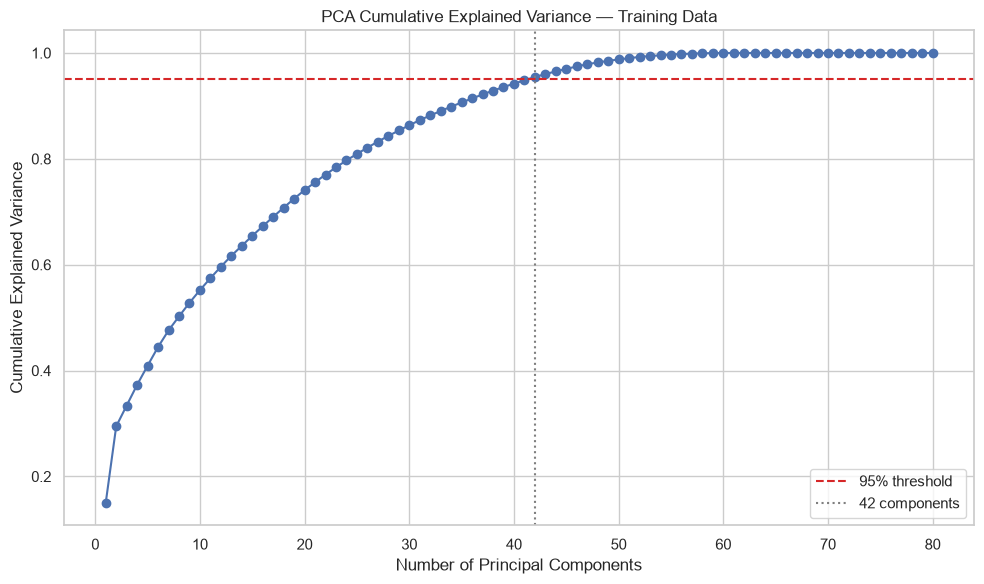

In [16]:
pca_scaler = StandardScaler()
X_train_scaled_for_pca = pca_scaler.fit_transform(X_train)
X_val_scaled_for_pca = pca_scaler.transform(X_val)

full_pca = PCA()
X_train_all_components = full_pca.fit_transform(X_train_scaled_for_pca)
X_val_all_components = full_pca.transform(X_val_scaled_for_pca)

cumulative_explained_variance = np.cumsum(full_pca.explained_variance_ratio_)
components_for_95_percent = int(
    np.argmax(cumulative_explained_variance >= 0.95) + 1
)

X_train_pca = X_train_all_components[:, :components_for_95_percent]
X_val_pca = X_val_all_components[:, :components_for_95_percent]

print("Original processed features:", X_train.shape[1])
print("Components for at least 95% variance:", components_for_95_percent)
print(
    "Explained variance retained:",
    cumulative_explained_variance[components_for_95_percent - 1],
)

plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_explained_variance) + 1),
    cumulative_explained_variance,
    marker="o",
)
plt.axhline(0.95, color="tab:red", linestyle="--", label="95% threshold")
plt.axvline(
    components_for_95_percent,
    color="tab:gray",
    linestyle=":",
    label=f"{components_for_95_percent} components",
)
plt.title("PCA Cumulative Explained Variance — Training Data")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pca_explained_variance.png", dpi=150)
plt.show()

In [17]:
pca_logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    random_state=RANDOM_STATE,
)
pca_logistic_model.fit(X_train_pca, y_train)
pca_predictions = pca_logistic_model.predict(X_val_pca)

pca_accuracy = accuracy_score(y_val, pca_predictions)
pca_macro_f1 = f1_score(y_val, pca_predictions, average="macro")

model_results.append(
    {
        "Model": "Logistic Regression + PCA",
        "Feature Set": f"{components_for_95_percent} components",
        "Scaling": "Standard",
        "Accuracy": pca_accuracy,
        "Macro F1": pca_macro_f1,
    }
)

pd.DataFrame(model_results).tail(1)

,Model,Feature Set,Scaling,Accuracy,Macro F1
5,Logistic Regression + PCA,42 components,Standard,0.487447,0.452276


### Finding

PCA compresses the processed data successfully, but its components are combinations rather than original football variables. Its validation result does not beat the strongest Gradient Boosting result enough to justify losing interpretability. The Top 40 original features therefore remain the selected modelling representation.

## 13. Scaling Experiment

Scaling matters for algorithms based on coefficients, distances, or margins, including Logistic Regression, SVM, and KNN. It is generally unnecessary for tree-based models such as Random Forest, Extra Trees, Gradient Boosting, and XGBoost.

We compare three versions of the same balanced Logistic Regression using **only `X_train_40` and `X_val_40`**:

1. **No Scaling** — the original Top 40 values.
2. **StandardScaler** — subtracts the training mean and divides by the training standard deviation.
3. **RobustScaler** — uses the training median and interquartile range, making it less sensitive to extreme values.

Each scaler is fitted only on `X_train_40`; validation data is transformed with the already-fitted scaler. The test season is not used.

In [18]:
scaling_datasets = {"No Scaling": (X_train_40, X_val_40)}

standard_scaler = StandardScaler()
scaling_datasets["StandardScaler"] = (
    standard_scaler.fit_transform(X_train_40),
    standard_scaler.transform(X_val_40),
)

robust_scaler = RobustScaler()
scaling_datasets["RobustScaler"] = (
    robust_scaler.fit_transform(X_train_40),
    robust_scaler.transform(X_val_40),
)

scaling_rows = []
for scaling_method, (scaled_train, scaled_val) in scaling_datasets.items():
    scaling_model = LogisticRegression(
        class_weight="balanced",
        max_iter=5000,
        random_state=RANDOM_STATE,
    )
    scaling_model.fit(scaled_train, y_train)
    scaling_predictions = scaling_model.predict(scaled_val)

    scaling_rows.append(
        {
            "Scaling Method": scaling_method,
            "Validation Accuracy": accuracy_score(y_val, scaling_predictions),
            "Validation Macro F1": f1_score(
                y_val,
                scaling_predictions,
                average="macro",
            ),
        }
    )

scaling_results = pd.DataFrame(scaling_rows)
best_scaling_row = scaling_results.loc[
    scaling_results["Validation Macro F1"].idxmax()
]
best_scaling_method = best_scaling_row["Scaling Method"]
no_scaling_macro_f1 = scaling_results.loc[
    scaling_results["Scaling Method"] == "No Scaling",
    "Validation Macro F1",
].iloc[0]
scaling_f1_gain = best_scaling_row["Validation Macro F1"] - no_scaling_macro_f1

display(scaling_results)
display(
    Markdown(
        f"### Scaling interpretation\n\n"
        f"**{best_scaling_method}** gives the highest validation Macro F1 "
        f"(`{best_scaling_row['Validation Macro F1']:.4f}`), with a change of "
        f"`{scaling_f1_gain:+.4f}` compared with no scaling. "
        + (
            "The change is smaller than 0.005, so scaling does not materially "
            "improve this Logistic Regression result; the numerical winner is "
            "kept only as the consistent preprocessing choice for scale-sensitive models."
            if abs(scaling_f1_gain) < 0.005
            else "The improvement is large enough to carry this scaler forward for scale-sensitive models."
        )
    )
)

,Scaling Method,Validation Accuracy,Validation Macro F1
0,No Scaling,0.485817,0.443022
1,StandardScaler,0.485817,0.443074
2,RobustScaler,0.485165,0.442304


### Scaling interpretation

**StandardScaler** gives the highest validation Macro F1 (`0.4431`), with a change of `+0.0001` compared with no scaling. The change is smaller than 0.005, so scaling does not materially improve this Logistic Regression result; the numerical winner is kept only as the consistent preprocessing choice for scale-sensitive models.

# Experimental Findings and Decisions

The final table below puts the major validation experiments in one place. Macro F1 is sorted first because balanced performance across the three outcomes is the main goal; accuracy is retained as supporting information.

In [19]:
for _, scaling_row in scaling_results.iterrows():
    model_results.append(
        {
            "Model": "Logistic Regression",
            "Feature Set": "Top 40",
            "Scaling": scaling_row["Scaling Method"],
            "Accuracy": scaling_row["Validation Accuracy"],
            "Macro F1": scaling_row["Validation Macro F1"],
        }
    )

model_comparison = (
    pd.DataFrame(model_results)
    .sort_values(["Macro F1", "Accuracy"], ascending=False)
    .reset_index(drop=True)
)
best_validation_model = model_comparison.iloc[0]
display(model_comparison)

display(
    Markdown(
        f"""
## Decisions carried into Notebook 05

- **Selected feature set:** Top 40 original, interpretable features. They retained about half of the processed columns while giving the strongest feature-count validation result.
- **Correlation/redundancy:** the two near-duplicate player-count columns were removed; highly related football ratings were retained for model-based evaluation rather than deleted automatically.
- **Mutual Information and forest importance:** both place relative team-strength differences near the top.
- **PCA:** retained at least 95% training variance but did not replace the interpretable Top 40 representation.
- **Class balancing:** materially improved Draw recall and Macro F1 compared with the initial unbalanced forest.
- **Draw threshold:** did not provide a worthwhile standalone improvement after its accuracy trade-off.
- **Best scaling method for scale-sensitive models:** **{best_scaling_method}**. Its advantage was negligible, so scaling is a consistency choice rather than the source of a major performance gain.
- **Best validation model so far:** **{best_validation_model['Model']}**, with validation accuracy **{best_validation_model['Accuracy']:.3f}** and Macro F1 **{best_validation_model['Macro F1']:.3f}**.
- **Test season (2015/16):** **not loaded or evaluated in this notebook**.

Notebook 05 will perform final candidate-model fitting and final model selection. The test season should be evaluated only after that choice is fixed.
"""
    )
)

,Model,Feature Set,Scaling,Accuracy,Macro F1
0,Gradient Boosting,All 80,None,0.473753,0.454516
1,Logistic Regression + PCA,42 components,Standard,0.487447,0.452276
2,Balanced Random Forest,Top 40,None,0.505380,0.444683
3,Logistic Regression,Top 40,StandardScaler,0.485817,0.443074
4,Logistic Regression,Top 40,No Scaling,0.485817,0.443022
5,Logistic Regression,Top 40,RobustScaler,0.485165,0.442304
6,Logistic Regression,All 80,Standard,0.483208,0.438263
7,Random Forest,All 80,None,0.511249,0.388879
8,Dummy (most frequent),All 80,None,0.447995,0.206260



## Decisions carried into Notebook 05

- **Selected feature set:** Top 40 original, interpretable features. They retained about half of the processed columns while giving the strongest feature-count validation result.
- **Correlation/redundancy:** the two near-duplicate player-count columns were removed; highly related football ratings were retained for model-based evaluation rather than deleted automatically.
- **Mutual Information and forest importance:** both place relative team-strength differences near the top.
- **PCA:** retained at least 95% training variance but did not replace the interpretable Top 40 representation.
- **Class balancing:** materially improved Draw recall and Macro F1 compared with the initial unbalanced forest.
- **Draw threshold:** did not provide a worthwhile standalone improvement after its accuracy trade-off.
- **Best scaling method for scale-sensitive models:** **StandardScaler**. Its advantage was negligible, so scaling is a consistency choice rather than the source of a major performance gain.
- **Best validation model so far:** **Gradient Boosting**, with validation accuracy **0.474** and Macro F1 **0.455**.
- **Test season (2015/16):** **not loaded or evaluated in this notebook**.

Notebook 05 will perform final candidate-model fitting and final model selection. The test season should be evaluated only after that choice is fixed.
